In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name.lower() == 'notebooks':
    ROOT = ROOT.parent
PROCESSED = ROOT / 'data' / 'processed'
AUDIT = ROOT / 'reports' / 'data_quality'
FIGURES = ROOT / 'reports' / 'figures' / 'final_eda'
HANDOFF = ROOT / 'reports' / 'modelling_handoff'
for p in (AUDIT, FIGURES, HANDOFF):
    p.mkdir(parents=True, exist_ok=True)

master_path = PROCESSED / 'listings_master.parquet'
feature_path = PROCESSED / 'listings_features.parquet'
if not master_path.exists():
    raise FileNotFoundError(f'Missing {master_path}; check your working folder.')

master = pd.read_parquet(master_path)
features = pd.read_parquet(feature_path) if feature_path.exists() else master.copy()
print('Project:', ROOT)
print('Source:', feature_path if feature_path.exists() else master_path)
print('Master shape:', master.shape, '| Current feature shape:', features.shape)
print('Columns:', list(features.columns))

required = {'id', 'location', 'country', 'room_type'}
missing = required - set(features.columns)
if missing:
    raise ValueError(f'Missing essential columns: {missing}')


Project: C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_
Source: C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_\data\processed\listings_features.parquet
Master shape: (756312, 93) | Current feature shape: (756312, 122)
Columns: ['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview', 'picture_url', 'host_id', 'host_url', 'host_profile_id', 'host_profile_url', 'host_name', 'host_since', 'hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_location', 'host_about', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed

In [2]:
def save_table(df, filename):
    path = AUDIT / filename
    df.to_csv(path, index=False, encoding='utf-8-sig')
    print('Saved', path)

summary = pd.DataFrame([{
    'master_rows': len(master),
    'features_rows': len(features),
    'locations': features['location'].nunique(dropna=True),
    'countries': features['country'].nunique(dropna=True),
    'duplicate_location_id_rows': int(features.duplicated(['location','id']).sum()),
    'duplicate_global_id_rows': int(features.duplicated(['id']).sum()),
    'unknown_country_rows': int(features['country'].astype('string').str.lower().eq('unknown').sum()),
}])
display(summary)
save_table(summary, 'dataset_integrity_summary.csv')

local_dups = features.loc[features.duplicated(['location','id'], keep=False),
                          [c for c in ['id','location','country','source_file'] if c in features.columns]]
save_table(local_dups.head(5000), 'duplicate_location_ids_examples.csv')

# One listing ID appearing in multiple source markets is a possible overlap.
overlap = (features.groupby('id', dropna=False)['location']
           .nunique(dropna=True).rename('n_locations').reset_index())
overlap = overlap.loc[overlap.n_locations > 1].sort_values('n_locations', ascending=False)
save_table(overlap.head(5000), 'cross_location_listing_id_overlap.csv')
print('IDs occurring in multiple locations:', len(overlap))

# Missingness by field and market; CSV output is easier for the team to inspect.
missing_by_col = pd.DataFrame({'column': features.columns,
                              'missing_n': features.isna().sum().values,
                              'missing_pct': (features.isna().mean().values * 100).round(2),
                              'dtype': features.dtypes.astype(str).values})
missing_by_col = missing_by_col.sort_values('missing_pct', ascending=False)
save_table(missing_by_col, 'missingness_by_column.csv')
display(missing_by_col.head(25))

important = [c for c in ['price', 'price_numeric', 'price_quote_price_per_night',
                           'latitude','longitude','room_type','accommodates','bedrooms',
                           'bathrooms_text', 'reviews_last_365d'] if c in features.columns]
missing_by_location = (features.groupby(['country','location'], dropna=False)[important]
                      .agg(lambda s: round(s.isna().mean()*100,2)).reset_index())
save_table(missing_by_location, 'missingness_by_location_pct.csv')


,master_rows,features_rows,locations,countries,duplicate_location_id_rows,duplicate_global_id_rows,unknown_country_rows
0,756312,756312,45,16,0,0,0


Saved C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_\reports\data_quality\dataset_integrity_summary.csv
Saved C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_\reports\data_quality\duplicate_location_ids_examples.csv
Saved C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_\reports\data_quality\cross_location_listing_id_overlap.csv
IDs occurring in multiple locations: 0
Saved C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_\reports\data_quality\missingness_by_column.csv


,column,missing_n,missing_pct,dtype
7,neighborhood_overview,756312,100.00,float64
14,host_since,756312,100.00,float64
21,host_response_time,756312,100.00,float64
25,host_thumbnail_url,756312,100.00,float64
23,host_acceptance_rate,756312,100.00,float64
22,host_response_rate,756312,100.00,float64
30,host_verifications,756312,100.00,float64
33,neighbourhood,756312,100.00,float64
29,host_total_listings_count,756312,100.00,float64
27,host_neighbourhood,756312,100.00,float64


Saved C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_\reports\data_quality\missingness_by_location_pct.csv


In [3]:
def parse_money(col):
    return pd.to_numeric(
        col.astype('string').str.replace(r'[^0-9.\-]', '', regex=True),
        errors='coerce'
    )

features['price_numeric'] = (pd.to_numeric(features['price_numeric'], errors='coerce')
                              if 'price_numeric' in features.columns
                              else parse_money(features['price']))
if 'price' in features.columns:
    raw_price = features['price'].astype('string')
    features['source_price_prefix'] = raw_price.str.extract(r'^\s*([^\d\s\-])', expand=False)
else:
    features['source_price_prefix'] = pd.NA

if 'price_quote_price_per_night' in features.columns:
    features['price_quote_numeric'] = parse_money(features['price_quote_price_per_night'])
else:
    features['price_quote_numeric'] = np.nan

price_audit = (features.groupby(['country','location'], dropna=False)
    .agg(n=('id','size'),
         valid_price=('price_numeric',lambda x: int(x.gt(0).sum())),
         median_price=('price_numeric','median'),
         p01_price=('price_numeric',lambda x: x.quantile(.01)),
         p99_price=('price_numeric',lambda x: x.quantile(.99)),
         median_quote=('price_quote_numeric','median'),
         missing_price_pct=('price_numeric',lambda x: round(x.isna().mean()*100,2)),
         zero_or_negative=('price_numeric',lambda x: int(x.le(0).sum())))
    .reset_index())
price_audit['median_quote_to_price_ratio'] = np.where(
    price_audit.median_price.gt(0),
    price_audit.median_quote / price_audit.median_price, np.nan)
save_table(price_audit, 'price_definition_market_audit.csv')
display(price_audit.sort_values('median_quote_to_price_ratio', na_position='last').head(15))

if 'price' in features.columns:
    prefix_audit = (features.groupby(['country','location','source_price_prefix'], dropna=False)
                    .size().rename('listings').reset_index())
    save_table(prefix_audit, 'price_prefixes_by_market.csv')

# Manual signoff required. Never switch this to True without checking units and source metadata.
PRICE_UNITS_VERIFIED = False
PRICE_TARGET_COLUMN = 'price_numeric'
print('WARNING: Price units unverified. Do not train a cross-market price model yet.' if not PRICE_UNITS_VERIFIED else 'Price signoff declared by analyst.')


Saved C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_\reports\data_quality\price_definition_market_audit.csv


,country,location,n,valid_price,median_price,p01_price,p99_price,median_quote,missing_price_pct,zero_or_negative,median_quote_to_price_ratio
0,Austria,Vienna,13283,10492,118.5,20.9746,592.18,118.5,21.01,0,1.0
1,Belgium,Antwerp,2535,2069,139.5,10.1596,784.7044,139.5,18.38,0,1.0
2,Belgium,Brussels,5078,4378,123.25,11.0885,730.7295,123.25,13.78,0,1.0
3,Belgium,Ghent,1383,1211,148.5,39.4,585.7,148.5,12.44,0,1.0
4,Czech Republic,Prague,11615,10583,2473.64,515.0,15027.8694,2473.64,8.89,0,1.0
5,Denmark,Copenhagen,23144,13860,1689.0,461.9031,6368.355,1689.0,40.11,0,1.0
6,France,Bordeaux,12217,8413,107.79,17.8804,665.9796,107.79,31.14,0,1.0
7,France,Lyon,9317,5427,103.68,24.84,568.37,103.68,41.75,0,1.0
8,France,Paris,77679,48402,205.5,29.87,1874.98,205.5,37.69,0,1.0
9,Germany,Berlin,12776,8441,130.67,9.208,632.3,130.67,33.93,0,1.0


Saved C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_\reports\data_quality\price_prefixes_by_market.csv


In [4]:
expected = [
 'price_numeric','accommodates_clean','bedrooms_clean','beds_clean','minimum_nights_clean',
 'bathrooms_numeric','amenities_count','has_wifi','has_air_conditioning','has_kitchen',
 'has_parking','has_pool','has_workspace','is_superhost','availability_rate_365',
 'competitors_500m','competitors_1km','competitors_2km','comparable_competitors_1km',
 'reviews_last_30d','reviews_last_90d','reviews_last_365d','days_since_last_review',
 'neighbourhood_listing_count','neighbourhood_host_count','location_listing_count',
 'market_median_price','neighbourhood_median_price','price_vs_neighbourhood_pct'
]
feat_audit = pd.DataFrame([{'feature':c,'present':c in features.columns,
                            'missing_pct': round(features[c].isna().mean()*100,2) if c in features else np.nan,
                            'dtype':str(features[c].dtype) if c in features else 'MISSING'}
                           for c in expected])
display(feat_audit)
save_table(feat_audit, 'engineered_feature_audit.csv')

checks=[]
def check(name, passed, detail=''):
    checks.append({'check':name,'passed':bool(passed),'detail':str(detail)})

check('Row count matches master', len(features)==len(master), f'{len(features)} vs {len(master)}')
check('Unique (location,id)', not features.duplicated(['location','id']).any())
check('No missing listing ID', features['id'].notna().all())
if {'latitude','longitude'}.issubset(features.columns):
    lat = pd.to_numeric(features.latitude,errors='coerce')
    lon = pd.to_numeric(features.longitude,errors='coerce')
    check('No invalid non-null coordinates',
          (~lat.notna() | lat.between(-90,90)).all() and (~lon.notna() | lon.between(-180,180)).all())
if {'competitors_500m','competitors_1km','competitors_2km'}.issubset(features.columns):
    comps=features[['competitors_500m','competitors_1km','competitors_2km']].apply(pd.to_numeric,errors='coerce').dropna()
    check('Competition counts monotone across radii',
          ((comps.competitors_500m <= comps.competitors_1km) &
           (comps.competitors_1km <= comps.competitors_2km) &
           comps.ge(0).all(axis=1)).all())
if 'availability_rate_365' in features.columns:
    a=pd.to_numeric(features.availability_rate_365,errors='coerce').dropna()
    check('Availability rate between 0 and 1', a.between(0,1).all())
if {'reviews_last_30d','reviews_last_90d','reviews_last_365d'}.issubset(features.columns):
    r=features[['reviews_last_30d','reviews_last_90d','reviews_last_365d']].apply(pd.to_numeric, errors='coerce').dropna()
    check('Review counts nonnegative and monotone',
          ((r.reviews_last_30d<=r.reviews_last_90d)&(r.reviews_last_90d<=r.reviews_last_365d)&r.ge(0).all(axis=1)).all())
check('Price units manually verified', PRICE_UNITS_VERIFIED, 'Analyst signoff required')
checks_df=pd.DataFrame(checks)
display(checks_df)
save_table(checks_df, 'quality_gates.csv')


,feature,present,missing_pct,dtype
0,price_numeric,True,19.25,Float64
1,accommodates_clean,True,0.00,int64
2,bedrooms_clean,True,16.51,float64
3,beds_clean,True,21.36,float64
4,minimum_nights_clean,True,0.01,float64
5,bathrooms_numeric,True,0.70,Float64
6,amenities_count,True,0.00,int64
7,has_wifi,True,0.00,int64
8,has_air_conditioning,True,0.00,int64
9,has_kitchen,True,0.00,int64


Saved C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_\reports\data_quality\engineered_feature_audit.csv


,check,passed,detail
0,Row count matches master,True,756312 vs 756312
1,"Unique (location,id)",True,
2,No missing listing ID,True,
3,No invalid non-null coordinates,True,
4,Competition counts monotone across radii,True,
5,Availability rate between 0 and 1,True,
6,Review counts nonnegative and monotone,True,
7,Price units manually verified,False,Analyst signoff required


Saved C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_\reports\data_quality\quality_gates.csv


In [5]:
eda = features.loc[features.price_numeric.gt(0)].copy()
eda['log1p_price'] = np.log1p(eda['price_numeric'])
# Per-market upper-percentile flag: descriptive only, not automatic deletion.
market_p99 = eda.groupby('location')['price_numeric'].transform(lambda x:x.quantile(.99))
eda['above_market_p99'] = eda.price_numeric > market_p99
outlier_audit = (eda.groupby(['country','location'],dropna=False)
                 .agg(priced_listings=('id','size'),above_market_p99=('above_market_p99','sum'),
                      median_price=('price_numeric','median'),max_price=('price_numeric','max'))
                 .reset_index())
save_table(outlier_audit, 'price_outlier_audit_by_market.csv')
print('Valid positive-price rows for EDA:', len(eda))


Saved C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_\reports\data_quality\price_outlier_audit_by_market.csv
Valid positive-price rows for EDA: 610663


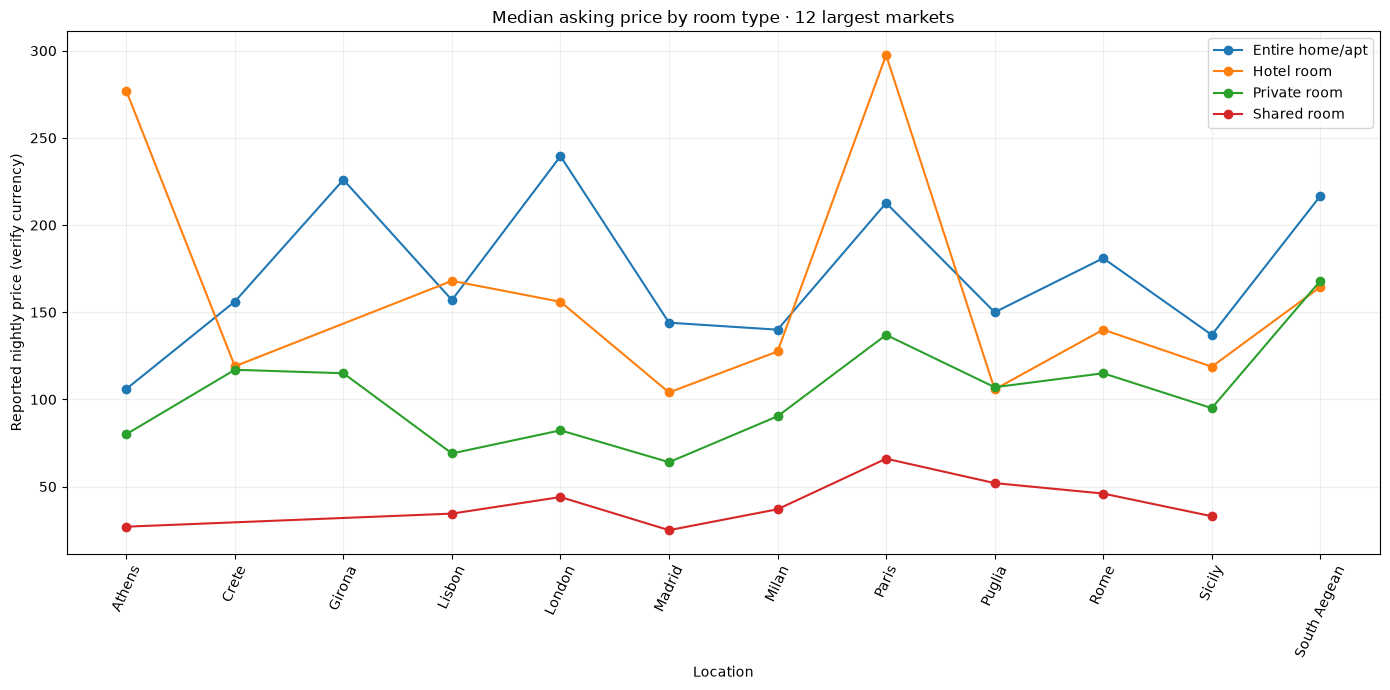

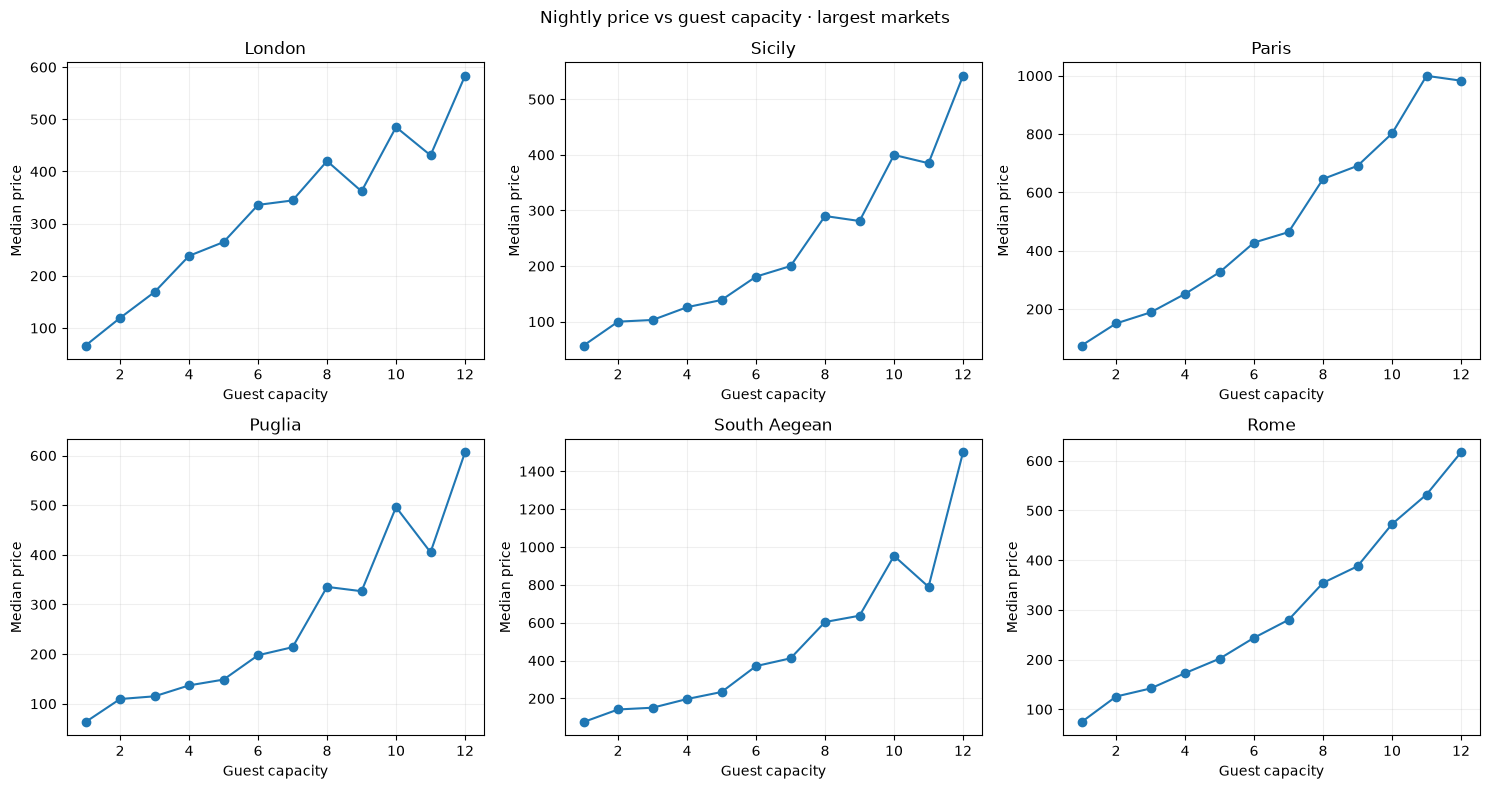

In [6]:
# Choose top markets by number of priced records to avoid unreadable figures.
top_markets = eda['location'].value_counts().head(12).index
plot_df = eda.loc[eda.location.isin(top_markets) & eda.room_type.notna()].copy()
price_room = (plot_df.groupby(['location','room_type'],observed=True)
              .agg(median_price=('price_numeric','median'),n=('id','size')).reset_index())
price_room=price_room.loc[price_room.n>=20]
fig,ax=plt.subplots(figsize=(14,7))
for room,part in price_room.groupby('room_type'):
    part=part.sort_values('location')
    ax.plot(part.location,part.median_price,marker='o',label=room)
ax.set(title='Median asking price by room type · 12 largest markets',xlabel='Location',ylabel='Reported nightly price (verify currency)')
ax.tick_params(axis='x',rotation=65); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(FIGURES/'price_by_room_type_top_markets.png',dpi=200,bbox_inches='tight');plt.show()

capacity_col = 'accommodates_clean' if 'accommodates_clean' in eda else ('accommodates' if 'accommodates' in eda else None)
if capacity_col:
    temp=eda[['location','price_numeric',capacity_col]].copy()
    temp['capacity']=pd.to_numeric(temp[capacity_col],errors='coerce')
    temp=temp[temp.capacity.between(1,12)]
    cap=temp.groupby(['location','capacity']).agg(median_price=('price_numeric','median'),n=('price_numeric','size')).reset_index()
    cap=cap[cap.n>=20]
    chosen=eda.location.value_counts().head(6).index
    fig,axes=plt.subplots(2,3,figsize=(15,8));axes=axes.ravel()
    for ax,location in zip(axes,chosen):
        sub=cap[cap.location==location].sort_values('capacity')
        ax.plot(sub.capacity,sub.median_price,marker='o');ax.set_title(location)
        ax.set(xlabel='Guest capacity',ylabel='Median price');ax.grid(alpha=.2)
    for ax in axes[len(chosen):]:ax.axis('off')
    fig.suptitle('Nightly price vs guest capacity · largest markets')
    fig.tight_layout();fig.savefig(FIGURES/'price_vs_capacity_markets.png',dpi=200,bbox_inches='tight');plt.show()


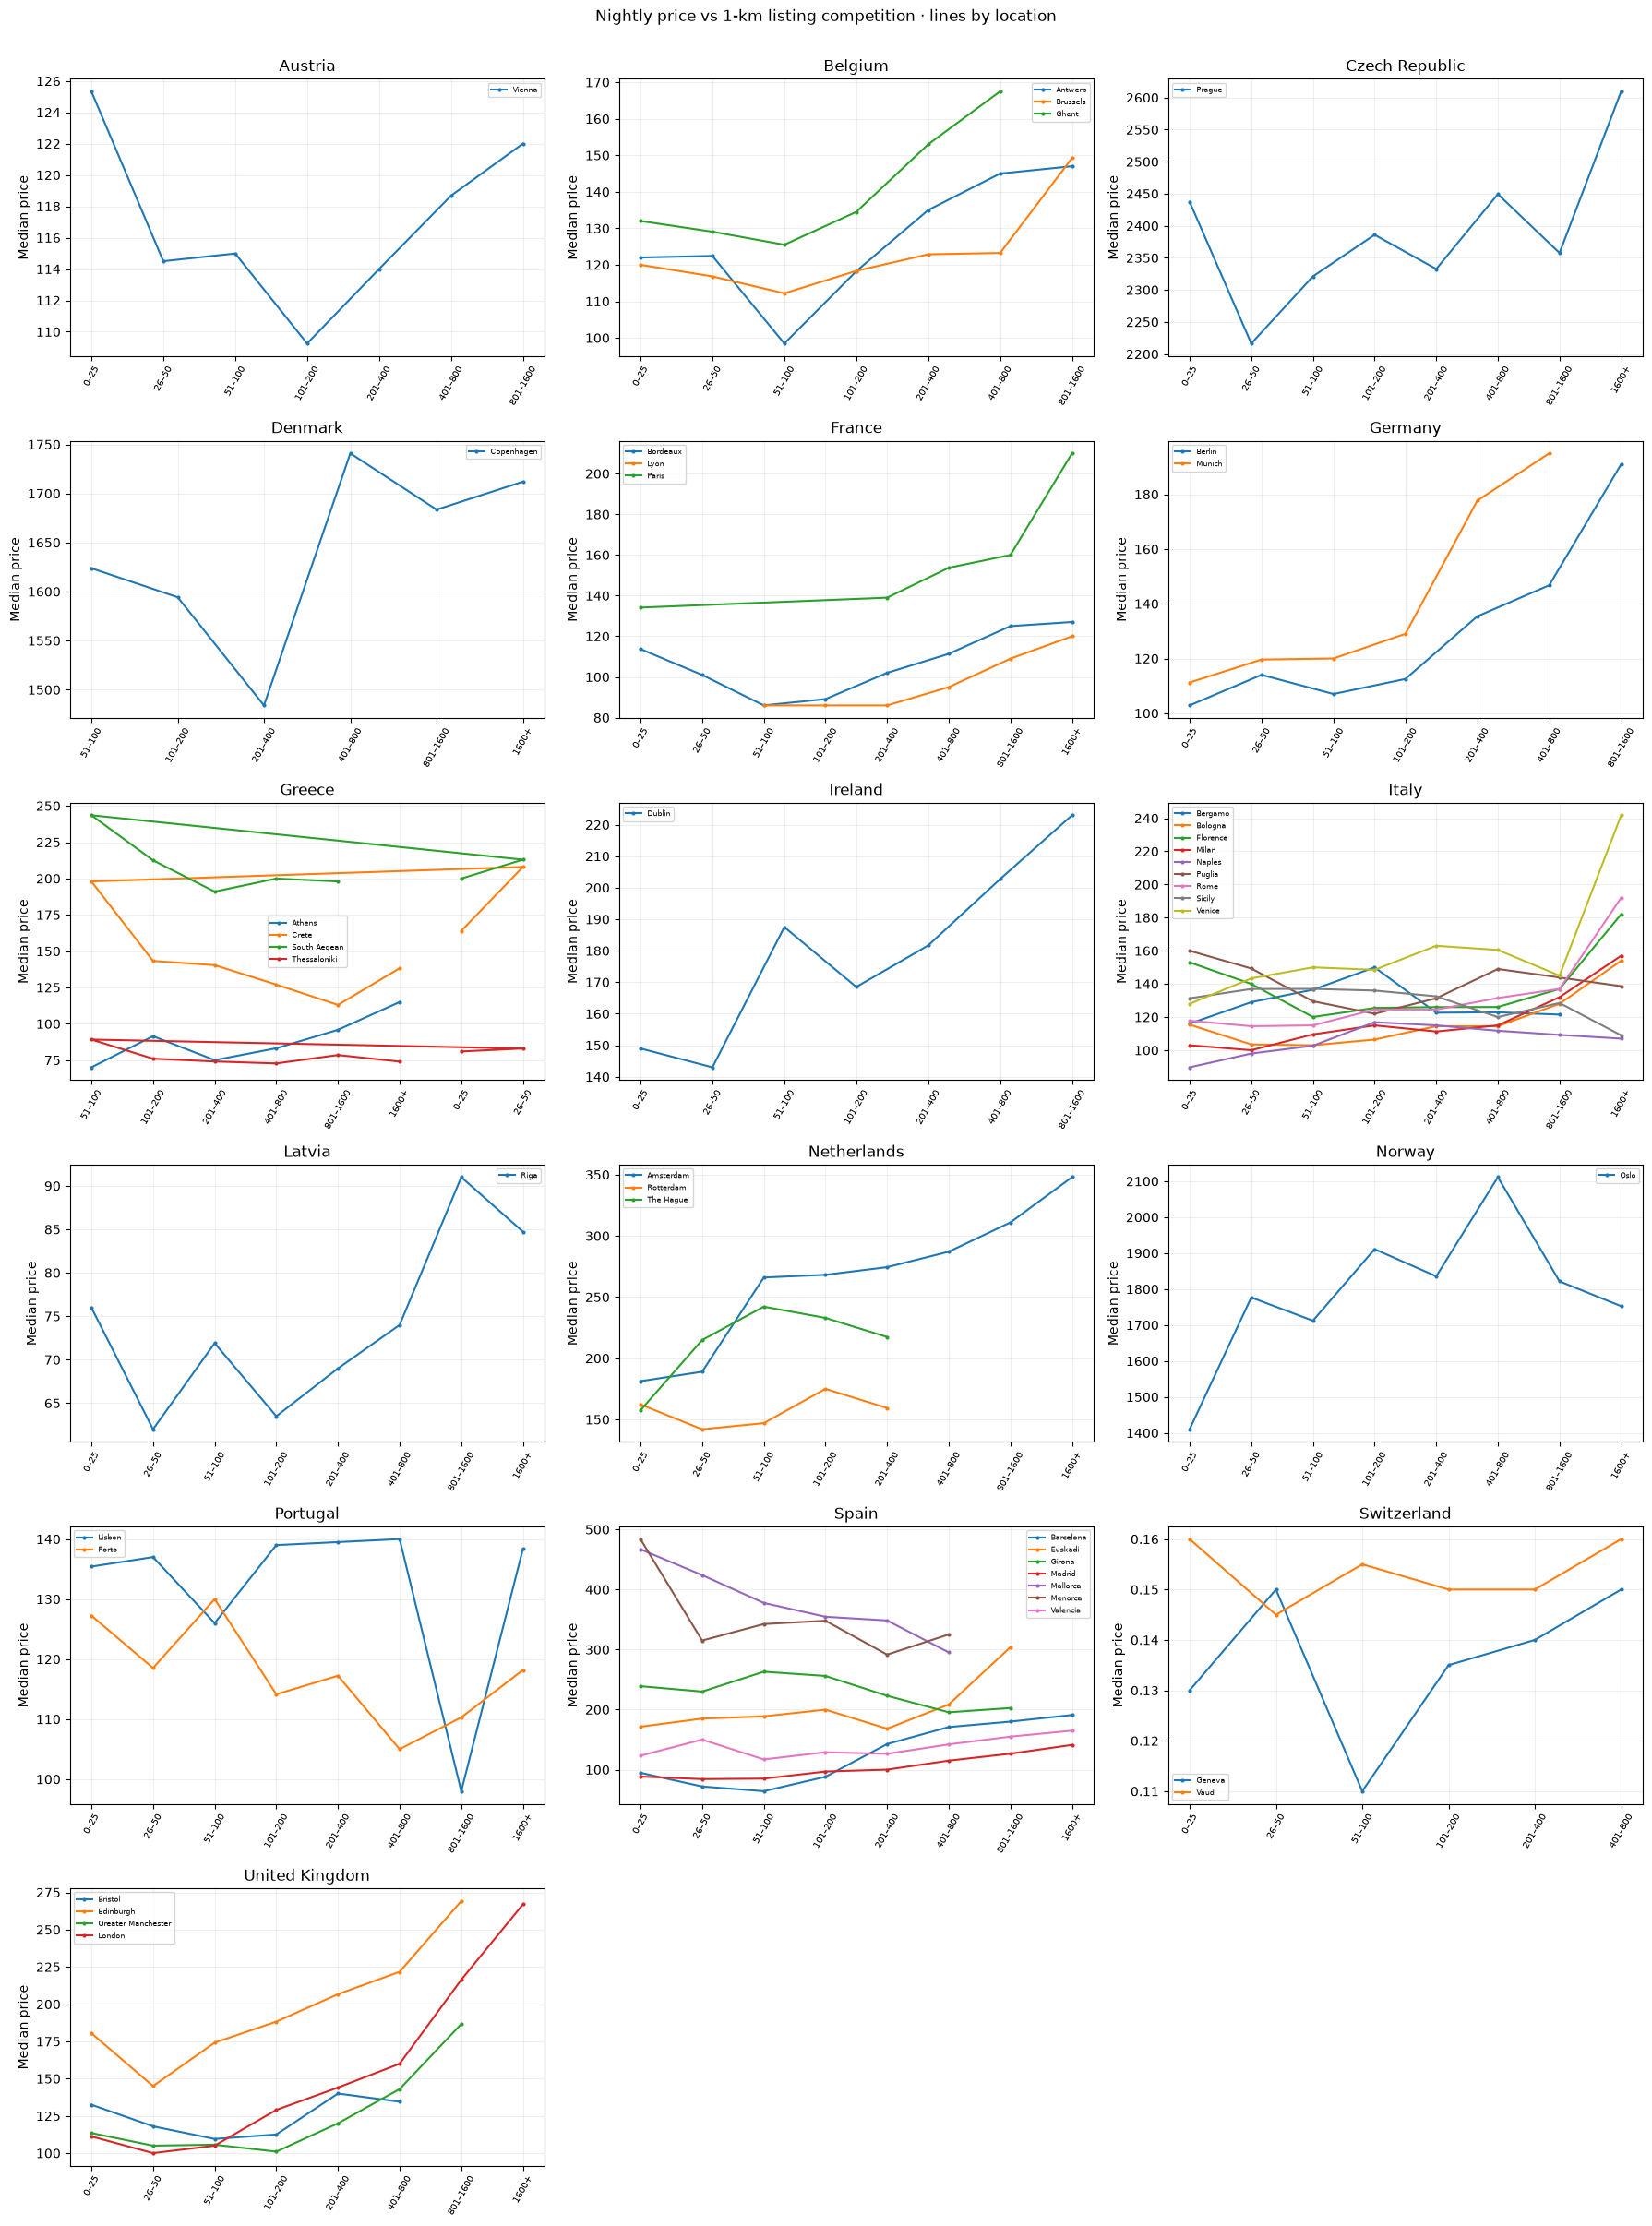

In [7]:
if 'competitors_1km' not in eda.columns:
    print('SKIPPED: competitors_1km missing. Run your feature-engineering notebook first.')
else:
    temp=eda[['country','location','room_type','price_numeric','competitors_1km']].copy()
    temp['competitors_1km']=pd.to_numeric(temp.competitors_1km,errors='coerce')
    temp=temp.dropna(subset=['competitors_1km','country','location'])
    temp=temp[temp.competitors_1km.ge(0)]
    # Quantile bins avoid extremely sparse bins caused by different city sizes.
    temp['competition_band']=pd.cut(temp.competitors_1km,
                                   bins=[-0.1,25,50,100,200,400,800,1600,np.inf],
                                   labels=['0–25','26–50','51–100','101–200','201–400','401–800','801–1600','1600+'])
    comp=(temp.groupby(['country','location','competition_band'],observed=True)
          .agg(median_price=('price_numeric','median'),n=('price_numeric','size')).reset_index())
    comp=comp[comp.n>=30]
    countries=sorted(comp.country.dropna().unique())
    import math
    ncols=3;nrows=math.ceil(len(countries)/ncols)
    fig,axes=plt.subplots(nrows,ncols,figsize=(18,max(4,nrows*4)),squeeze=False)
    for ax,country in zip(axes.ravel(),countries):
        d=comp[comp.country==country]
        for loc,s in d.groupby('location'):
            s=s.sort_values('competition_band')
            ax.plot(s.competition_band.astype(str),s.median_price,marker='o',markersize=2,label=loc)
        ax.set_title(country);ax.grid(alpha=.2)
        ax.tick_params(axis='x',rotation=60,labelsize=7)
        ax.set_ylabel('Median price')
        if d.location.nunique()>0:ax.legend(fontsize=6)
    for ax in axes.ravel()[len(countries):]:ax.axis('off')
    fig.suptitle('Nightly price vs 1-km listing competition · lines by location',y=1.003)
    fig.tight_layout();fig.savefig(FIGURES/'price_vs_competition_country_panels.png',dpi=200,bbox_inches='tight');plt.show()
    comp.to_csv(AUDIT/'competition_price_binned_summary.csv',index=False)


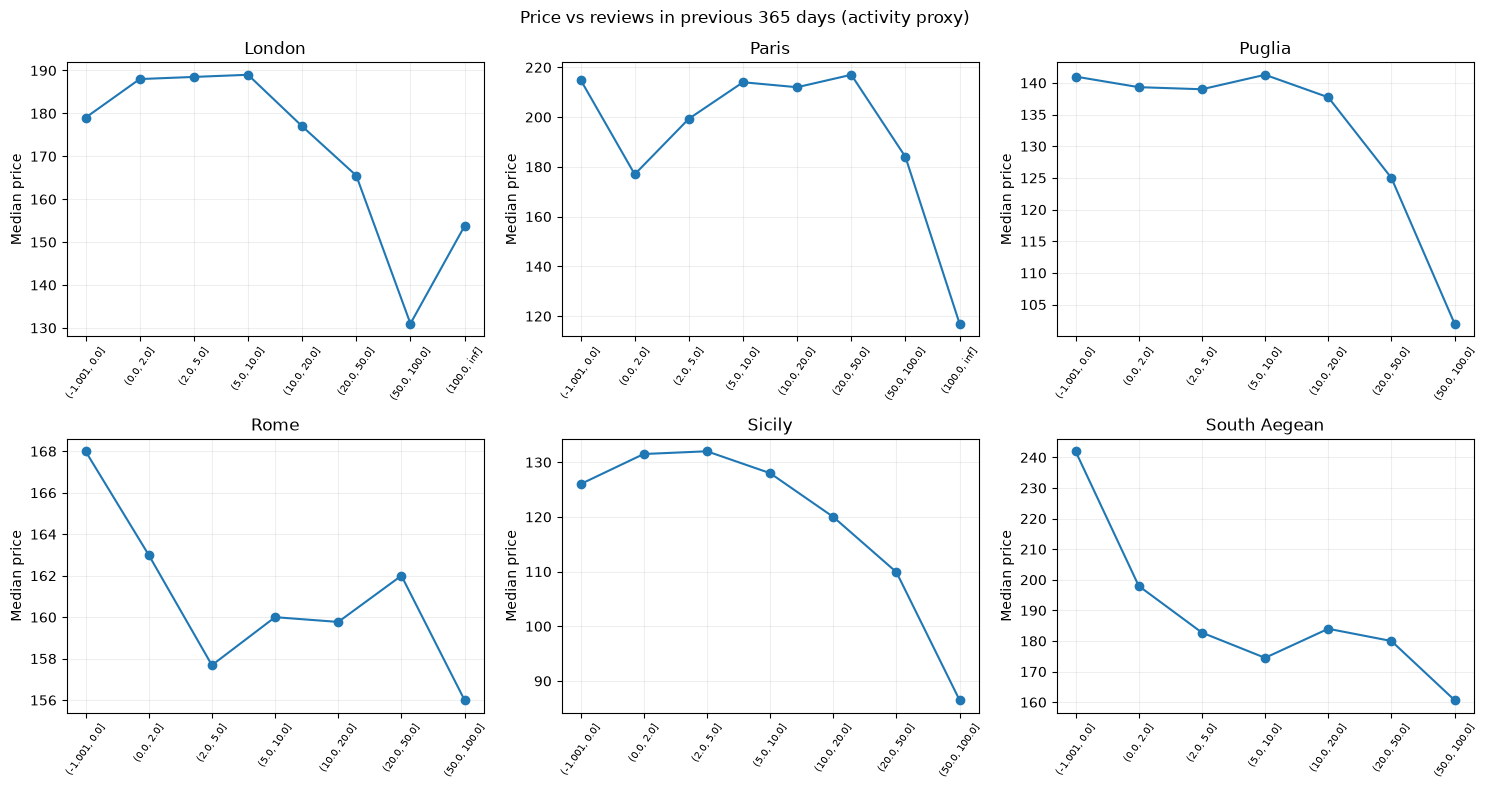

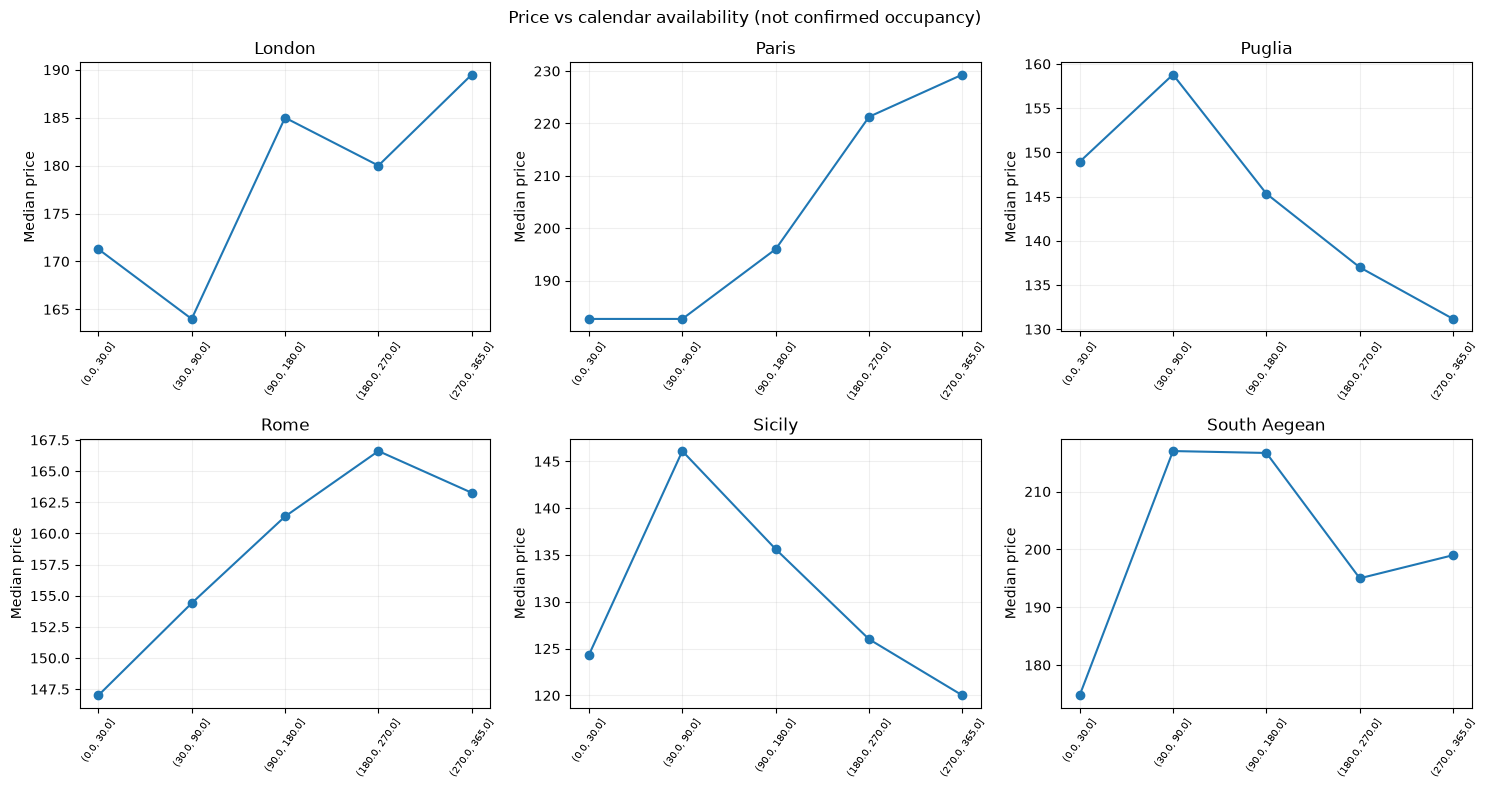

In [8]:
def binned_price_plot(source, column, filename, title, bins):
    p=source[['location','price_numeric',column]].copy()
    p[column]=pd.to_numeric(p[column],errors='coerce')
    p=p.dropna()
    if p.empty: return
    p['band']=pd.cut(p[column],bins=bins,include_lowest=True)
    p=p[p.location.isin(p.location.value_counts().head(6).index)]
    summary=(p.groupby(['location','band'],observed=True)
             .agg(median_price=('price_numeric','median'),n=('price_numeric','size')).reset_index())
    summary=summary[summary.n>=20]
    fig,axes=plt.subplots(2,3,figsize=(15,8));axes=axes.ravel()
    for ax,loc in zip(axes,sorted(p.location.unique())[:6]):
        s=summary[summary.location==loc].sort_values('band')
        ax.plot(s.band.astype(str),s.median_price,marker='o');ax.set_title(loc)
        ax.tick_params(axis='x',rotation=55,labelsize=7);ax.set_ylabel('Median price');ax.grid(alpha=.2)
    fig.suptitle(title);fig.tight_layout();fig.savefig(FIGURES/filename,dpi=200,bbox_inches='tight');plt.show()

if 'reviews_last_365d' in eda:
    binned_price_plot(eda,'reviews_last_365d','price_vs_review_activity.png',
                      'Price vs reviews in previous 365 days (activity proxy)',
                      [-1,0,2,5,10,20,50,100,np.inf])
else:
    print('SKIPPED review relationship: reviews_last_365d is absent')

if 'availability_365' in eda:
    binned_price_plot(eda,'availability_365','price_vs_availability.png',
                      'Price vs calendar availability (not confirmed occupancy)',
                      [-1,0,30,90,180,270,365])


In [9]:
TARGET = PRICE_TARGET_COLUMN
numeric_predictors = [
  'accommodates_clean','bedrooms_clean','beds_clean','bathrooms_numeric',
  'minimum_nights_clean','amenities_count','has_wifi','has_air_conditioning',
  'has_kitchen','has_parking','has_pool','has_workspace','is_superhost',
  'competitors_500m','competitors_1km','competitors_2km','comparable_competitors_1km'
]
categorical_predictors=['country','location','room_type','property_type']
# Review recency, ratings, availability and host behavior require an availability-time decision.
conditional_predictors = ['reviews_last_90d','reviews_last_365d',
                          'days_since_last_review','availability_rate_365','host_listing_count']
investment_only = ['price_vs_neighbourhood_pct','market_median_price',
                   'neighbourhood_median_price','price_quote_numeric']

available_predictors=[c for c in numeric_predictors+categorical_predictors if c in features]
available_conditional=[c for c in conditional_predictors if c in features]
cols=['location','id',TARGET] + available_predictors + available_conditional
cols=list(dict.fromkeys(cols))
model_candidate = features.loc[features[TARGET].gt(0),cols].copy()
for c in available_predictors:
    if c in numeric_predictors:
        model_candidate[c] = pd.to_numeric(model_candidate[c],errors='coerce')
# No random global imputation/scaling: those should be fit only on training folds.
model_candidate.to_parquet(PROCESSED/'model_candidate.parquet',index=False,compression='zstd')
print('Saved provisional model candidate:',model_candidate.shape)
print('Conditional columns (exclude unless validated):',available_conditional)
print('Investment-only columns deliberately excluded:',investment_only)
print('APPROVED FOR TRAINING?', PRICE_UNITS_VERIFIED and bool(checks_df.passed.all()))


Saved provisional model candidate: (610663, 27)
Conditional columns (exclude unless validated): ['reviews_last_90d', 'reviews_last_365d', 'days_since_last_review', 'availability_rate_365']
Investment-only columns deliberately excluded: ['price_vs_neighbourhood_pct', 'market_median_price', 'neighbourhood_median_price', 'price_quote_numeric']
APPROVED FOR TRAINING? False


In [10]:
import json
handoff = {
 'analysis_date':str(pd.Timestamp.today().date()),
 'source_parquets':['listings_master.parquet','reviews_clean.parquet','listings_features.parquet'],
 'model_candidate_file':str(PROCESSED/'model_candidate.parquet'),
 'target':TARGET,
 'price_units_verified':PRICE_UNITS_VERIFIED,
 'training_approved':bool(PRICE_UNITS_VERIFIED and checks_df.passed.all()),
 'candidate_predictors':available_predictors,
 'conditional_predictors_do_not_use_without_review':available_conditional,
 'explicitly_excluded_from_X':investment_only + ['id','price','price_numeric','price_per_guest'],
 'critical_notes':[
   'Confirm price target semantics, units and currency before pooling markets.',
   'Investigate overlapping source regions and repeated global listing IDs.',
   'Compute any supervised price aggregates inside training folds; not on full data.',
   'Review dates must precede the predictor cutoff for historical evaluation.',
   'Unavailable calendar nights are not confirmed bookings or occupancy.',
   'Data splitting, imputation and encoding must be fit on training data only.'
 ],
 'failed_quality_gates':checks_df.loc[~checks_df.passed,'check'].tolist()
}
(HANDOFF/'handoff_manifest.json').write_text(json.dumps(handoff,indent=2,ensure_ascii=False),encoding='utf-8')

# Feature dictionary: documented roles for exported candidates.
rows=[]
for col in model_candidate.columns:
    role=('target' if col==TARGET else 'identifier' if col=='id' else
          'conditional_predictor' if col in available_conditional else 'predictor_candidate')
    rows.append({'feature':col,'role':role,'dtype':str(model_candidate[col].dtype),
                 'missing_pct':round(model_candidate[col].isna().mean()*100,2)})
fd=pd.DataFrame(rows)
fd.to_csv(HANDOFF/'feature_dictionary.csv',index=False,encoding='utf-8-sig')
display(fd)

print('Export complete. Examine:')
print(' -',AUDIT)
print(' -',FIGURES)
print(' -',HANDOFF)
print(' -',PROCESSED/'model_candidate.parquet')
if not handoff['training_approved']:
    print('STATUS: Provisional. Resolve flagged quality gates before the modelling team trains a cross-market price model.')


,feature,role,dtype,missing_pct
0,location,predictor_candidate,str,0.00
1,id,identifier,Int64,0.00
2,price_numeric,target,Float64,0.00
3,accommodates_clean,predictor_candidate,int64,0.00
4,bedrooms_clean,predictor_candidate,float64,15.11
5,beds_clean,predictor_candidate,float64,6.55
6,bathrooms_numeric,predictor_candidate,Float64,0.72
7,minimum_nights_clean,predictor_candidate,float64,0.01
8,amenities_count,predictor_candidate,int64,0.00
9,has_wifi,predictor_candidate,int64,0.00


Export complete. Examine:
 - C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_\reports\data_quality
 - C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_\reports\figures\final_eda
 - C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_\reports\modelling_handoff
 - C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_\data\processed\model_candidate.parquet
STATUS: Provisional. Resolve flagged quality gates before the modelling team trains a cross-market price model.


In [12]:
from pathlib import Path
import pandas as pd

# Find the Airbnb project directory
PROJECT_ROOT = Path.cwd().resolve()

# If running from the notebooks folder, move to project root
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

print("Project root:", PROJECT_ROOT)
quality_gates = pd.read_csv(
    PROJECT_ROOT / "reports" / "data_quality" / "quality_gates.csv"
)

display(quality_gates)
print("Columns:", quality_gates.columns.tolist())

Project root: C:\Users\erins\OneDrive\Documents\Airbnb_VSCode_Project\Airbnb_EDACode_Project_


,check,passed,detail
0,Row count matches master,True,756312 vs 756312
1,"Unique (location,id)",True,NaN
2,No missing listing ID,True,NaN
3,No invalid non-null coordinates,True,NaN
4,Competition counts monotone across radii,True,NaN
5,Availability rate between 0 and 1,True,NaN
6,Review counts nonnegative and monotone,True,NaN
7,Price units manually verified,False,Analyst signoff required


Columns: ['check', 'passed', 'detail']


In [13]:
price_audit = pd.read_csv(
    PROJECT_ROOT / "reports" / "data_quality"
    / "price_definition_market_audit.csv"
)

display(price_audit)

,country,location,n,valid_price,median_price,p01_price,p99_price,median_quote,missing_price_pct,zero_or_negative,median_quote_to_price_ratio
0,Austria,Vienna,13283,10492,118.500,20.9746,592.1800,118.500,21.01,0,1.00000
1,Belgium,Antwerp,2535,2069,139.500,10.1596,784.7044,139.500,18.38,0,1.00000
2,Belgium,Brussels,5078,4378,123.250,11.0885,730.7295,123.250,13.78,0,1.00000
3,Belgium,Ghent,1383,1211,148.500,39.4000,585.7000,148.500,12.44,0,1.00000
4,Czech Republic,Prague,11615,10583,2473.640,515.0000,15027.8694,2473.640,8.89,0,1.00000
5,Denmark,Copenhagen,23144,13860,1689.000,461.9031,6368.3550,1689.000,40.11,0,1.00000
6,France,Bordeaux,12217,8413,107.790,17.8804,665.9796,107.790,31.14,0,1.00000
7,France,Lyon,9317,5427,103.680,24.8400,568.3700,103.680,41.75,0,1.00000
8,France,Paris,77679,48402,205.500,29.8700,1874.9800,205.500,37.69,0,1.00000
9,Germany,Berlin,12776,8441,130.670,9.2080,632.3000,130.670,33.93,0,1.00000


In [14]:
import pandas as pd

suspect_markets = [
    "Prague",
    "Copenhagen",
    "Oslo",
    "Geneva",
    "Vaud"
]

columns = [
    "country",
    "location",
    "id",
    "price",
    "price_numeric",
    "price_quote_price_per_night"
]

available = [c for c in columns if c in features.columns]

# Original values and processed values side by side
sample = (
    features.loc[
        features["location"].isin(suspect_markets),
        available
    ]
    .groupby("location", group_keys=False)
    .head(10)
)

display(sample)

,country,location,id,price,price_numeric,price_quote_price_per_night
84813,Denmark,Copenhagen,1192561049767674816,"$1,159.00",1159.0,1159.00
84814,Denmark,Copenhagen,1448618670473676599,"$1,832.50",1832.5,1832.50
84815,Denmark,Copenhagen,1468213160712999671,"$2,533.50",2533.5,2533.50
84816,Denmark,Copenhagen,746991123879164604,NaN,<NA>,NaN
84817,Denmark,Copenhagen,1663937964630857937,"$1,812.91",1812.91,1812.91
84818,Denmark,Copenhagen,926859407049575277,$279.51,279.51,279.51
84819,Denmark,Copenhagen,1431272739184874230,"$1,326.67",1326.67,1326.67
84820,Denmark,Copenhagen,1510039720935950133,"$1,662.77",1662.77,1662.77
84821,Denmark,Copenhagen,1444692614253710721,"$1,673.00",1673.0,1673.00
84822,Denmark,Copenhagen,1686440282487599655,"$2,087.33",2087.33,2087.33


In [15]:
price_diagnostics = (
    features[
        features["location"].isin(suspect_markets)
    ]
    .groupby("location")["price_numeric"]
    .agg(
        count="count",
        min="min",
        median="median",
        max="max"
    )
    .round(3)
)

display(price_diagnostics)

,count,min,median,max
location,,,,
Copenhagen,13860,45.16,1689.0,42931.33
Geneva,1600,0.0,0.14,0.99
Oslo,9841,61.65,1819.0,91294.16
Prague,10583,63.87,2473.64,1191906.33
Vaud,3119,0.0,0.15,0.99


In [18]:
swiss = features[
    features["location"].isin(["Geneva", "Vaud"])
].copy()

columns = [
    "location",
    "id",
    "price",
    "price_numeric",
    "price_quote_price_per_night"
]

columns = [c for c in columns if c in swiss.columns]

display(
    swiss[columns].sample(
        n=min(25, len(swiss)),
        random_state=42
    )
)

,location,id,price,price_numeric,price_quote_price_per_night
170472,Geneva,1532635424375746466,$0.05,0.05,0.05
169786,Geneva,1137585232155199397,$0.29,0.29,0.29
731620,Vaud,815162784305243535,NaN,<NA>,NaN
732954,Vaud,1371788109513090117,$0.23,0.23,0.23
731544,Vaud,776379893809900873,$0.06,0.06,0.06
729269,Vaud,10198358,$0.52,0.52,0.52
733976,Vaud,1695705302994782824,$0.23,0.23,0.23
169674,Geneva,1075171743078761059,$0.11,0.11,0.11
170308,Geneva,1485463039126812169,$0.14,0.14,0.14
170571,Geneva,1596615420345668966,$0.07,0.07,0.07


In [19]:
for location in ["Geneva", "Vaud"]:

    subset = features[
        features["location"] == location
    ]

    print(f"\n{location}")
    print("Original price examples:")

    display(
        subset["price"]
        .dropna()
        .astype(str)
        .value_counts()
        .head(20)
    )


Geneva
Original price examples:


price
$0.13    105
$0.14    100
$0.15     92
$0.11     91
$0.12     88
$0.10     70
$0.17     69
$0.16     68
$0.02     60
$0.19     58
$0.18     51
$0.01     50
$0.03     45
$0.07     42
$0.08     38
$0.09     38
$0.23     37
$0.22     36
$0.20     34
$0.21     30
Name: count, dtype: int64


Vaud
Original price examples:


price
$0.12    155
$0.14    152
$0.19    137
$0.03    131
$0.13    119
$0.04    118
$0.16    118
$0.17    118
$0.15    115
$0.02    110
$0.06    108
$0.10    101
$0.11     97
$0.05     88
$0.08     87
$0.18     76
$0.20     75
$0.07     72
$0.09     72
$0.21     72
Name: count, dtype: int64

In [21]:
for location in ["Geneva", "Vaud"]:

    values = features.loc[
        features["location"] == location,
        "price_numeric"
    ].dropna()

    print(f"\n{location}")

    print("Sample values:")
    print(values.sample(
        n=min(20, len(values)),
        random_state=42
    ).tolist())

    print("Percentiles:")
    print(
        values.quantile(
            [0, .01, .05, .25, .50, .75, .95, .99, 1]
        )
    )


Geneva
Sample values:
[0.11, 0.16, 0.88, 0.82, 0.15, 0.05, 0.15, 0.31, 0.02, 0.11, 0.02, 0.1, 0.08, 0.35, 0.2, 0.1, 0.59, 0.02, 0.07, 0.14]
Percentiles:
0.00       0.0
0.01      0.01
0.05      0.02
0.25       0.1
0.50      0.14
0.75      0.21
0.95      0.75
0.99    0.9401
1.00      0.99
Name: price_numeric, dtype: Float64

Vaud
Sample values:
[0.06, 0.21, 0.92, 0.28, 0.58, 0.07, 0.09, 0.21, 0.12, 0.02, 0.11, 0.31, 0.14, 0.38, 0.24, 0.04, 0.24, 0.21, 0.1, 0.22]
Percentiles:
0.00      0.0
0.01     0.01
0.05     0.02
0.25     0.09
0.50     0.15
0.75     0.24
0.95    0.731
0.99     0.93
1.00     0.99
Name: price_numeric, dtype: Float64


In [22]:
features["price_target_usable"] = (
    features["price_numeric"].notna()
    & (features["price_numeric"] > 0)
    & ~features["location"].isin(["Geneva", "Vaud"])
)

In [16]:
# Markets requiring price-unit investigation
suspect_markets = [
    "Prague",
    "Copenhagen",
    "Oslo",
    "Geneva",
    "Vaud"
]

features["price_units_unverified"] = (
    features["location"].isin(suspect_markets)
)

# Flag invalid target prices
features["invalid_target_price"] = (
    features["price_numeric"].isna()
    | (features["price_numeric"] <= 0)
)

display(
    features.groupby(
        ["country", "location"]
    )[["price_units_unverified", "invalid_target_price"]]
    .agg(["sum", "mean"])
)

price_units_unverified       \
                                                     sum mean   
country        location                                         
Austria        Vienna                                  0  0.0   
Belgium        Antwerp                                 0  0.0   
               Brussels                                0  0.0   
               Ghent                                   0  0.0   
Czech Republic Prague                              11615  1.0   
Denmark        Copenhagen                          23144  1.0   
France         Bordeaux                                0  0.0   
               Lyon                                    0  0.0   
               Paris                                   0  0.0   
Germany        Berlin                                  0  0.0   
               Munich                                  0  0.0   
Greece         Athens                                  0  0.0   
               Crete                                   0  0.0   
               South Aegean                            0  0.0   
               Thessaloniki                            0  0.0   
Ireland        Dublin                                  0  0.0   
Italy          Bergamo                                 0  0.0   
               Bologna                                 0  0.0   
               Florence                                0  0.0   
               Milan                                   0  0.0   
               Naples                                  0  0.0   
               Puglia                                  0  0.0   
               Rome                                    0  0.0   
               Sicily                                  0  0.0   
               Venice                                  0  0.0   
Latvia         Riga                                    0  0.0   
Netherlands    Amsterdam                               0  0.0   
               Rotterdam                               0  0.0   
               The Hague                               0  0.0   
Norway         Oslo                                13391  1.0   
Portugal       Lisbon                                  0  0.0   
               Porto                                   0  0.0   
Spain          Barcelona                               0  0.0   
               Euskadi                                 0  0.0   
               Girona                                  0  0.0   
               Madrid                                  0  0.0   
               Mallorca                                0  0.0   
               Menorca                                 0  0.0   
               Valencia                                0  0.0   
Switzerland    Geneva                               2593  1.0   
               Vaud                                 5295  1.0   
United Kingdom Bristol                                 0  0.0   
               Edinburgh                               0  0.0   
               Greater Manchester                      0  0.0   
               London                                  0  0.0   

                                  invalid_target_price            
                                                   sum      mean  
country        location                                           
Austria        Vienna                             2791  0.210118  
Belgium        Antwerp                             466  0.183826  
               Brussels                            700   0.13785  
               Ghent                               172  0.124367  
Czech Republic Prague                             1032  0.088851  
Denmark        Copenhagen                         9284  0.401141  
France         Bordeaux                           3804  0.311369  
               Lyon                               3890  0.417516  
               Paris                             29277  0.376897  
Germany        Berlin                             4335  0.339308  
               Munich                     

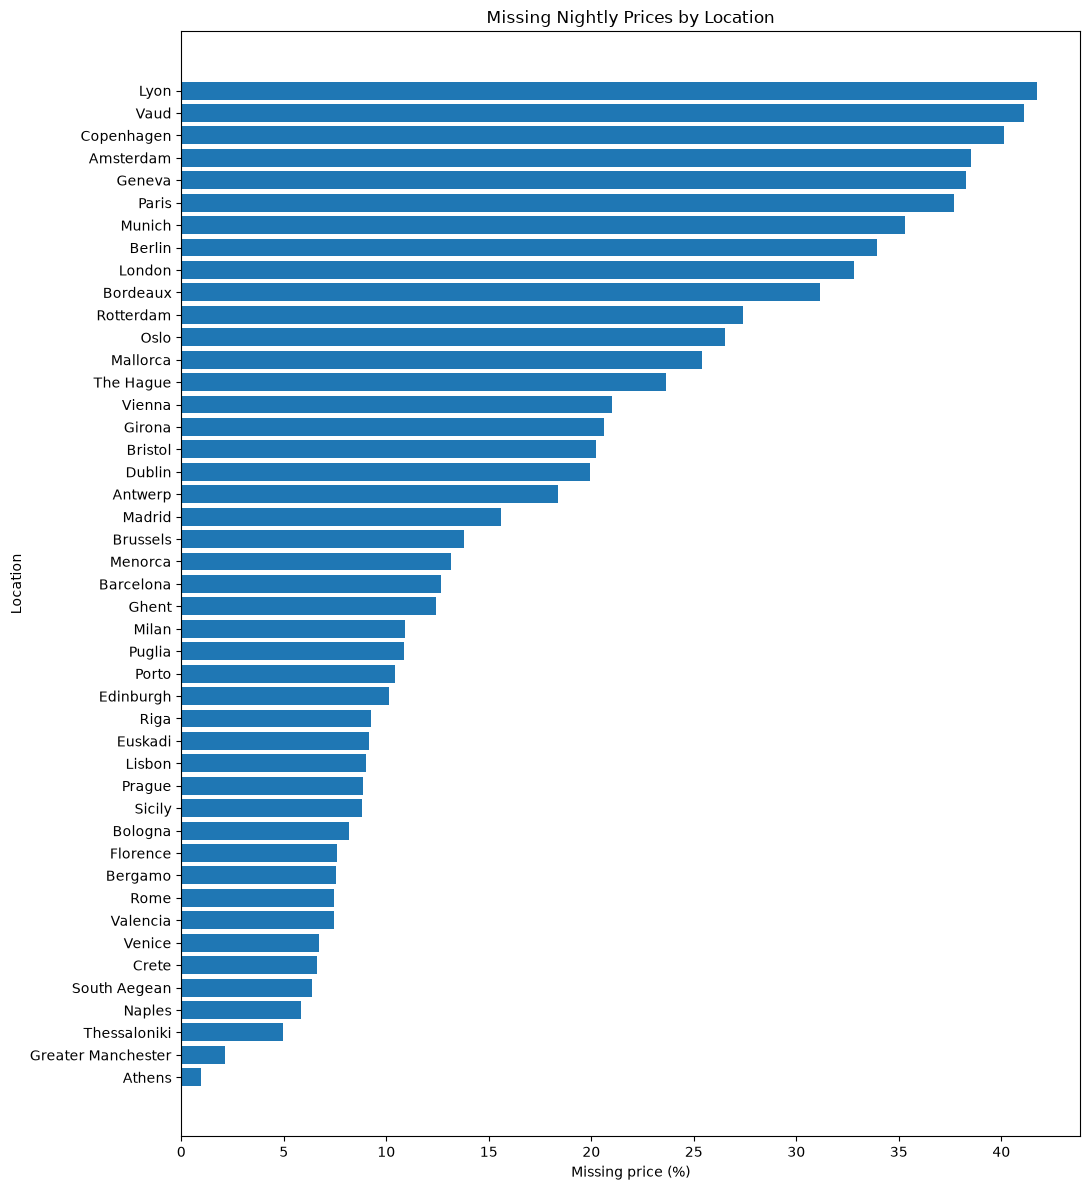

In [17]:
import matplotlib.pyplot as plt

missing_price_by_location = (
    features.groupby("location")["price_numeric"]
    .apply(lambda x: x.isna().mean() * 100)
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(11, 12))

ax.barh(
    missing_price_by_location.index,
    missing_price_by_location.values
)

ax.set_title("Missing Nightly Prices by Location")
ax.set_xlabel("Missing price (%)")
ax.set_ylabel("Location")

plt.tight_layout()

output_folder = PROJECT_ROOT / "reports" / "figures" / "final_eda"
output_folder.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_folder / "missing_prices_by_location.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
features["price_numeric"] = pd.to_numeric(
    features["price_numeric"],
    errors="coerce"
)

features["price_missing"] = features["price_numeric"].isna()

features["price_nonpositive"] = (
    features["price_numeric"].notna()
    & (features["price_numeric"] <= 0)
)

features["invalid_target_price"] = (
    features["price_missing"]
    | features["price_nonpositive"]
)

price_quality = (
    features.groupby(["country", "location"])
    .agg(
        total_listings=("id", "size"),
        missing_prices=("price_missing", "sum"),
        nonpositive_prices=("price_nonpositive", "sum"),
        invalid_prices=("invalid_target_price", "sum")
    )
    .reset_index()
)

price_quality["invalid_pct"] = (
    price_quality["invalid_prices"]
    / price_quality["total_listings"] * 100
).round(2)

display(
    price_quality.sort_values(
        "invalid_pct", ascending=False
    )
)

,country,location,total_listings,missing_prices,nonpositive_prices,invalid_prices,invalid_pct
7,France,Lyon,9317,3890,0,3890,41.75
40,Switzerland,Vaud,5295,2176,19,2195,41.45
5,Denmark,Copenhagen,23144,9284,0,9284,40.11
39,Switzerland,Geneva,2593,993,13,1006,38.8
26,Netherlands,Amsterdam,10369,3992,0,3992,38.5
8,France,Paris,77679,29277,0,29277,37.69
10,Germany,Munich,6865,2425,0,2425,35.32
9,Germany,Berlin,12776,4335,0,4335,33.93
44,United Kingdom,London,92638,30398,0,30398,32.81
6,France,Bordeaux,12217,3804,0,3804,31.14


In [24]:
suspect_markets = {
    "Prague": "local_currency_unverified",
    "Copenhagen": "local_currency_unverified",
    "Oslo": "local_currency_unverified",
    "Geneva": "scaling_error_suspected",
    "Vaud": "scaling_error_suspected"
}

features["price_verification_status"] = (
    features["location"]
    .map(suspect_markets)
    .fillna("currency_verification_pending")
)

display(
    features.groupby(
        ["location", "price_verification_status"]
    ).size().reset_index(name="listings")
)

,location,price_verification_status,listings
0,Amsterdam,currency_verification_pending,10369
1,Antwerp,currency_verification_pending,2535
2,Athens,currency_verification_pending,14337
3,Barcelona,currency_verification_pending,15293
4,Bergamo,currency_verification_pending,4237
5,Berlin,currency_verification_pending,12776
6,Bologna,currency_verification_pending,4948
7,Bordeaux,currency_verification_pending,12217
8,Bristol,currency_verification_pending,3023
9,Brussels,currency_verification_pending,5078


In [31]:

import pandas as pd
import numpy as np

# Use the original integrated Parquet rather than the enriched features
listings_master = pd.read_parquet(
    PROCESSED / "listings_master.parquet"
)

country_currency = {
    "Austria": "EUR",
    "Belgium": "EUR",
    "Czech Republic": "CZK",
    "Denmark": "DKK",
    "France": "EUR",
    "Germany": "EUR",
    "Greece": "EUR",
    "Ireland": "EUR",
    "Italy": "EUR",
    "Latvia": "EUR",
    "Netherlands": "EUR",
    "Norway": "NOK",
    "Portugal": "EUR",
    "Spain": "EUR",
    "Switzerland": "CHF",
    "United Kingdom": "GBP"
}

# Create a fresh audit dataframe
price_audit = listings_master[
    ["country", "location", "id", "price"]
].copy()

# Expected currency based on location — not independently verified
price_audit["expected_currency"] = (
    price_audit["country"].map(country_currency)
)

# Inspect the original stored price values
price_audit["price_from_original"] = pd.to_numeric(
    price_audit["price"]
    .astype("string")
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

# Attach processed price for comparison
processed = features[
    ["country", "location", "id", "price_numeric"]
].copy()

price_audit = price_audit.merge(
    processed,
    on=["country", "location", "id"],
    how="left",
    validate="one_to_one"
)

# Compare nonmissing values
price_audit["price_matches"] = np.isclose(
    price_audit["price_from_original"].astype(float),
    pd.to_numeric(
        price_audit["price_numeric"], errors="coerce"
    ).astype(float),
    rtol=0,
    atol=0.01,
    equal_nan=True
)

# Market-level summary
currency_audit = (
    price_audit.groupby(
        ["country", "location", "expected_currency"],
        dropna=False
    )
    .agg(
        listings=("id", "size"),
        median_price=("price_from_original", "median"),
        price_match_pct=("price_matches", lambda x: x.mean() * 100),
        missing_price_pct=("price_from_original", lambda x: x.isna().mean() * 100)
    )
    .reset_index()
)

display(currency_audit)

,country,location,expected_currency,listings,median_price,price_match_pct,missing_price_pct
0,Austria,Vienna,EUR,13283,118.5,100.0,21.01182
1,Belgium,Antwerp,EUR,2535,139.5,100.0,18.382643
2,Belgium,Brussels,EUR,5078,123.25,100.0,13.784955
3,Belgium,Ghent,EUR,1383,148.5,100.0,12.436732
4,Czech Republic,Prague,CZK,11615,2473.64,100.0,8.885062
5,Denmark,Copenhagen,DKK,23144,1689.0,100.0,40.114068
6,France,Bordeaux,EUR,12217,107.79,100.0,31.13694
7,France,Lyon,EUR,9317,103.68,100.0,41.751637
8,France,Paris,EUR,77679,205.5,100.0,37.689723
9,Germany,Berlin,EUR,12776,130.67,100.0,33.930808


In [ ]:
currency_audit["verification_status"] = "INTERNAL_MATCH_ONLY"

currency_audit.loc[
    currency_audit["price_match_pct"] < 99.9,
    "verification_status"
] = "PRICE_TRANSFORMATION_MISMATCH"

currency_audit.loc[
    currency_audit["expected_currency"].isna(),
    "verification_status"
] = "UNKNOWN_EXPECTED_CURRENCY"

currency_audit.loc[
    currency_audit["location"].isin(["Geneva", "Vaud"]),
    "verification_status"
] = "SWISS_PRICE_SCALE_UNRESOLVED"

display(
    currency_audit[
        [
            "country",
            "location",
            "expected_currency",
            "median_price",
            "price_match_pct",
            "verification_status"
        ]
    ]
)

In [28]:

audit_results = []
raw_price_samples = []

for (country, location), group in features.groupby(
    ["country", "location"], dropna=False
):

    filepath = RAW_DIR / f"{location}_listings.csv"

    result = {
        "country": country,
        "location": location,
        "expected_currency": country_currency.get(country),
        "listings": len(group),
        "raw_file_found": filepath.exists(),
        "raw_price_match_pct": np.nan,
        "processed_median": pd.to_numeric(
            group["price_numeric"], errors="coerce"
        ).median()
    }

    if filepath.exists():
        raw = pd.read_csv(
            filepath,
            dtype=str,
            usecols=lambda c: c in {
                "id", "price", "currency"
            }
        )

        if {"id", "price"}.issubset(raw.columns):
            raw["id"] = raw["id"].astype("string").str.strip()
            raw["raw_price_numeric"] = raw["price"].map(parse_price)

            processed = group[["id", "price_numeric"]].copy()
            processed["id"] = (
                processed["id"].astype("string").str.strip()
            )

            # Do not silently resolve conflicting source IDs
            duplicate_raw_ids = raw["id"].duplicated().sum()
            result["duplicate_raw_ids"] = duplicate_raw_ids

            if duplicate_raw_ids == 0:
                comparison = processed.merge(
                    raw[["id", "price", "raw_price_numeric"]],
                    on="id",
                    how="left",
                    validate="many_to_one"
                )

                processed_num = pd.to_numeric(
                    comparison["price_numeric"],
                    errors="coerce"
                )

                raw_num = comparison["raw_price_numeric"]

                both_valid = (
                    processed_num.notna() & raw_num.notna()
                )

                if both_valid.any():
                    matches = np.isclose(
                        processed_num[both_valid].astype(float),
                        raw_num[both_valid].astype(float),
                        rtol=0,
                        atol=0.01
                    )

                    result["raw_price_match_pct"] = (
                        matches.mean() * 100
                    )

                result["raw_median"] = raw_num.median()
                result["matched_rows"] = int(both_valid.sum())

                raw_price_samples.append(
                    comparison.assign(
                        location=location
                    ).head(10)
                )

            if "currency" in raw.columns:
                codes = (
                    raw["currency"]
                    .dropna()
                    .astype(str)
                    .str.upper()
                    .str.strip()
                    .unique()
                    .tolist()
                )
                result["raw_currency_codes"] = ",".join(codes)

    audit_results.append(result)

currency_audit = pd.DataFrame(audit_results)

display(
    currency_audit.sort_values(
        ["country", "location"]
    )
)


,country,location,expected_currency,listings,raw_file_found,raw_price_match_pct,processed_median
0,Austria,Vienna,EUR,13283,False,NaN,118.500
1,Belgium,Antwerp,EUR,2535,False,NaN,139.500
2,Belgium,Brussels,EUR,5078,False,NaN,123.250
3,Belgium,Ghent,EUR,1383,False,NaN,148.500
4,Czech Republic,Prague,CZK,11615,False,NaN,2473.640
5,Denmark,Copenhagen,DKK,23144,False,NaN,1689.000
6,France,Bordeaux,EUR,12217,False,NaN,107.790
7,France,Lyon,EUR,9317,False,NaN,103.680
8,France,Paris,EUR,77679,False,NaN,205.500
9,Germany,Berlin,EUR,12776,False,NaN,130.670


In [32]:
REPORT_DIR = (
    PROJECT_ROOT / "reports" / "data_quality"
)

REPORT_DIR.mkdir(parents=True, exist_ok=True)

currency_audit.to_csv(
    REPORT_DIR / "currency_verification_audit.csv",
    index=False
)

print("Saved revised currency audit.")


Saved revised currency audit.
